<table border=0 width="100%"><tr><td><p align="left"><img src="..\img\logo.png" align="left" width=300></p></td><td><font size=3><B>Evaluate trading strategy (Haichao Zheng)</B></font></td></tr></table>

Today's topics
- EMH and active trading
- Good Day Sunshine: Stock Returns and the Weather
- why do we care about Sharpe Ratio?
- how to caculate Sharpe Ratio?
- max drawdown
- put all together
- additional considerations for evaluating investment strategies
- evaluate your trading strategy after class

# EMH and active trading

1965年，美国芝加哥大学金融学教授尤金·法玛(Eugene Fama，1939－）发表了题为《股票市场价格行为》的博士毕业论文，于1970年对该理论进行了深化，并提出有效市场假说（Efficient Markets Hypothesis，简称EMH）。

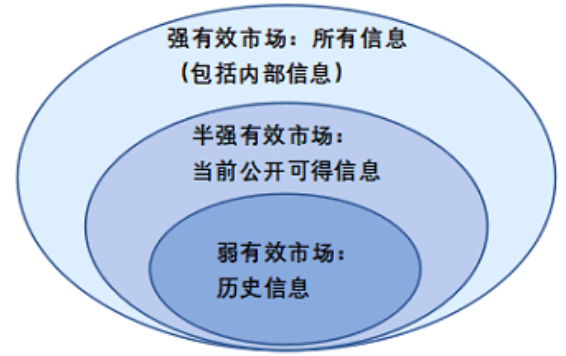

- 弱式有效市场假说(Weak-Form Market Efficiency)

市场价格已充分反映出所有过去历史的证券价格信息，包括股票的成交价、成交量，卖空金额、融资金额等；只使用历史价格和成交量数据不能战胜市场

- 半强式有效市场假说(Semi-Strong-Form Market Efficiency)

价格已充分反映出所有已公开的有关公司营运前景的信息。这些信息有成交价、成交量、盈利资料、盈利预测值、公司管理状况及其它公开披露的财务信息等。只使用公开信息，比如历史价格、基本面信息等不能战胜市场。

- 强式有效市场假说(Strong-Form Market Efficiency)

强式有效市场假说认为价格已充分地反映了所有关于公司营运的信息，这些信息包括已公开的或内部未公开的信息。无论如何都不能战胜市场，市场价格包含了一切相关信息。

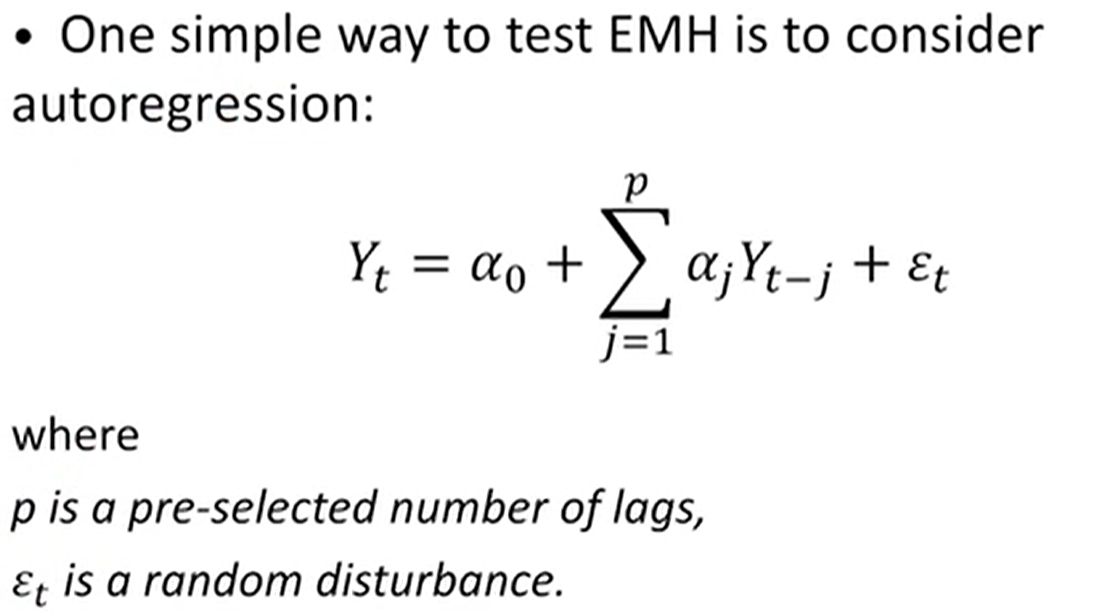

In [1]:
import tushare as ts
import pandas as pd
import numpy as np
token = 'aa6d7dba75bcd6eccd5bbda27e0cf6cf56c4759ec767990bdb041575'
ts.set_token(token)
pro = ts.pro_api()

start_date='20010101'
end_date='20230505'

index_daily = pro.index_daily(ts_code='000001.SH', start_date=start_date, end_date=end_date)
index_daily.trade_date = pd.DatetimeIndex(index_daily.trade_date)
index_daily.set_index("trade_date",inplace=True)
index_daily.sort_index(inplace=True)

In [2]:
log_return = index_daily.close.apply(np.log).diff()
index_daily["log_return"] = log_return

In [3]:
lags = 10
cols=  []
for lag in range(1,lags+1):
    col = "log_return_lag_{}".format(lag)
    index_daily[col] = log_return.shift(lag)
    cols.append(col)
cols

['log_return_lag_1',
 'log_return_lag_2',
 'log_return_lag_3',
 'log_return_lag_4',
 'log_return_lag_5',
 'log_return_lag_6',
 'log_return_lag_7',
 'log_return_lag_8',
 'log_return_lag_9',
 'log_return_lag_10']

In [4]:
index_daily.dropna(inplace=True)
index_daily.head()

,ts_code,close,open,high,low,pre_close,change,pct_chg,vol,amount,...,log_return_lag_1,log_return_lag_2,log_return_lag_3,log_return_lag_4,log_return_lag_5,log_return_lag_6,log_return_lag_7,log_return_lag_8,log_return_lag_9,log_return_lag_10
trade_date,,,,,,,,,,,,,,,,,,,,,
2001-01-17,000001.SH,2034.584,2046.377,2048.695,2031.756,2045.887,-11.303,-0.5525,7324134.0,6609475.901,...,0.006593,-0.034957,-0.006816,-0.003050,0.011583,-0.000442,-0.010993,0.003722,-0.003062,0.009666
2001-01-18,000001.SH,2043.110,2033.686,2049.355,2033.576,2034.584,8.526,0.4191,10341571.0,8381612.881,...,-0.005540,0.006593,-0.034957,-0.006816,-0.003050,0.011583,-0.000442,-0.010993,0.003722,-0.003062
2001-01-19,000001.SH,2065.606,2046.581,2067.877,2046.541,2043.110,22.496,1.1011,11831264.0,8601583.114,...,0.004182,-0.005540,0.006593,-0.034957,-0.006816,-0.003050,0.011583,-0.000442,-0.010993,0.003722
2001-02-05,000001.SH,2008.032,2069.856,2072.547,2005.683,2065.606,-57.574,-2.7873,8974243.0,7400294.453,...,0.010950,0.004182,-0.005540,0.006593,-0.034957,-0.006816,-0.003050,0.011583,-0.000442,-0.010993
2001-02-06,000001.SH,1995.315,1999.723,1999.725,1956.178,2008.032,-12.717,-0.6333,9528427.0,7974362.139,...,-0.028269,0.010950,0.004182,-0.005540,0.006593,-0.034957,-0.006816,-0.003050,0.011583,-0.000442


In [ ]:
index_daily.columns

In [5]:
# # !pip install statsmodels
import statsmodels.api as sm

In [6]:
import matplotlib.pyplot as plt

X = index_daily.loc[:,cols].values
y = np.array(index_daily["log_return"])
X = sm.add_constant(X)
results = sm.OLS(y,X).fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.007
Model:                            OLS   Adj. R-squared:                  0.005
Method:                 Least Squares   F-statistic:                     3.629
Date:                Fri, 12 May 2023   Prob (F-statistic):           7.80e-05
Time:                        14:30:19   Log-Likelihood:                 15020.
No. Observations:                5404   AIC:                        -3.002e+04
Df Residuals:                    5393   BIC:                        -2.995e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       8.594e-05      0.000      0.420      0.674      -0.000       0.000
x1             0.0193      0.014      1.416      0.157      -0.007       0.046
x2            -0.0183      0.014     -1.343      0.179      -0.045       0.008
x3             0.0285      0.014      2.090      0.037       0.002       0.055
x4             0.0405      0.014      2.976      0.003       0.014       0.067
x5            -0.0038      0.014     -0.277      0.782      -0.030       0.023
x6            -0.0483      0.014     -3.549      0.000      -0.075      -0.022
x7             0.0314      0.014      2.304      0.021       0.005       0.058
x8             0.0003      0.014      0.022      0.983      -0.026       0.027
x9             0.0049      0.014      0.363      0.717      -0.022       0.032
x10           -0.0005      0.014     -0.035      0.972      -0.027       0.026
==============================================================================
Omnibus:                      726.101   Durbin-Watson:                   2.000
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             5892.471
Skew:                          -0.379   Prob(JB):                         0.00
Kurtosis:                       8.059   Cond. No.                         70.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

<BarContainer object of 10 artists>

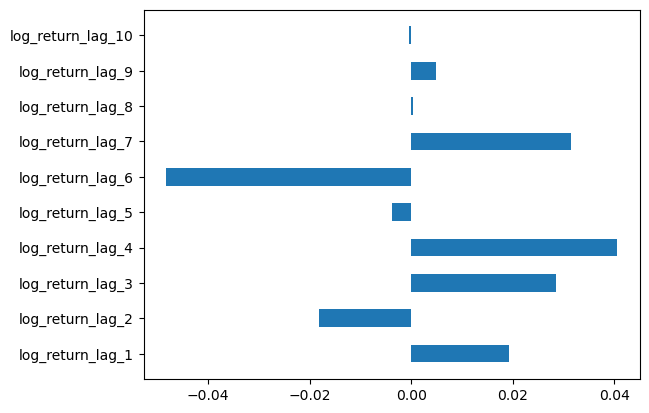

In [7]:
plt.barh(cols, list(results.params[1:]),height=0.5)

有效市场假说有一个颇受质疑的前提假设，即参与市场的投资者有足够的理性，并且能够迅速对所有市场信息作出合理反应。

There are various reasons why the Efficient Markets Hypothesis (EMH) may not hold. Some of the reasons are:

- Behavioral Biases: Behavioral biases such as overconfidence, anchoring, and herding behavior can lead to irrational market behavior, which can cause market inefficiencies.

- Information Asymmetry: Information asymmetry arises when some investors have access to information that is not publicly available, leading to market inefficiencies.

- Market Frictions: Market frictions such as transaction costs, taxes, and restrictions on short-selling can hinder the efficient pricing of assets.

- Technical Analysis: The use of technical analysis by traders and investors can result in market inefficiencies as technical indicators are often based on past prices and do not necessarily reflect the intrinsic value of assets.

# Good Day Sunshine: Stock Returns and the Weather
- rain 
- snow
- sunshine
- wind

How to create trading strategy based on sunshine?

# why do we care about Sharpe Ratio?

## Sharpe Ratio
Sharpe Ratio是一个经济学上的指标，用来衡量资产或投资组合的风险调整后的收益率。它由诺贝尔经济学奖得主威廉·莫顿·夏普（William F. Sharpe）提出。

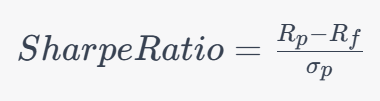
 

其中，$R_p$是投资组合的预期收益率，$R_f$是无风险收益率，$\sigma_p$是投资组合收益率的标准差。

Sharpe Ratio的经济直观含义是，对于每承担一个单位的风险，可以获得多少的超额收益，单位为比率。例如，Sharpe Ratio为1表示承担一个单位的风险，可以获得一个单位的超额收益。

这个指标的优点在于它将投资组合的表现与市场整体表现以及市场风险进行比较。Sharpe Ratio越高，表示投资组合的表现越好，因为每承担一定的风险，它能够获得更多的超额收益。在进行资产配置和选择投资组合时，Sharpe Ratio可以帮助投资者比较不同投资组合的表现，并选择具有更高Sharpe Ratio的投资组合。

## Markowitz portfolio optimization

假设有N个资产，每个资产的收益率为$R_i$，风险为$\sigma_i$，权重为$w_i$，且$\sum_{i=1}^{N} w_i = 1$。

投资组合的收益率为所有资产的收益率加权平均，即$R_p = \sum_{i=1}^{N} w_iR_i$。

投资组合的方差为所有资产方差和两两资产之间的协方差的加权和，即$\sigma_p^2 = \sum_{i=1}^{N} \sum_{j=1}^{N} w_iw_j\rho_{ij}\sigma_i\sigma_j$。

投资者的目标是在给定风险水平的情况下最大化投资组合的收益率。因此，可以将目标函数表示为：

$max_w R_p - \lambda\sigma_p^2$

其中，$\lambda$ 是一个非负的调节参数，用来控制风险和收益的权衡关系。

投资者可以通过求解最优权重向量$w^*$来实现最大化投资组合收益率的目标。


效用函数参数$\lambda>0$表示风险规避





## exercise in class
按照Markowitz portfolio optimization，我们简化一下问题：在只有一种无风险资产和一种风险资产的情况下，如何计算投资组合权重？

## how to rank a Sharpe Ratio?

根据基金业协会的数据，美国公募基金经理的Sharpe Ratio中位数通常在0.5至1.0之间。然而，这个数字可能因不同类型基金（如股票型基金、债券型基金等）而有所不同。

给Sharpe Ratio打一个级别（rank）的方法并不唯一，不同的机构和行业可能会有不同的标准。一种可能的方法是根据Sharpe Ratio的大小将其分为几个级别，例如：

- 优秀：大于2.0
- 良好：1.0至2.0
- 一般：0.5至1.0
- 较差：0至0.5

# how to caculate Sharpe Ratio?

## data

<AxesSubplot:xlabel='trade_date'>

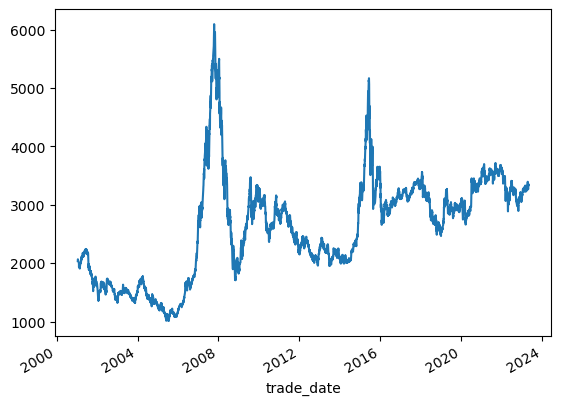

In [8]:
index_daily.close.plot()

In [9]:
import numpy as np
buy_and_hold_reuturn = index_daily.close.apply(np.log).diff()
buy_and_hold_reuturn = buy_and_hold_reuturn.dropna()

In [10]:
buy_and_hold_reuturn

trade_date
2001-01-18    0.004182
2001-01-19    0.010950
2001-02-05   -0.028269
2001-02-06   -0.006353
2001-02-07   -0.007736
                ...   
2023-04-26   -0.000236
2023-04-27    0.006652
2023-04-28    0.011315
2023-05-04    0.008147
2023-05-05   -0.004774
Name: close, Length: 5403, dtype: float64

## annualized_return

算术收益率（Arithmetic Return）和对数收益率（Logarithmic Return）在计算方式上有所不同，因此它们的年化收益率（Annualized Return）结果可能会有较大差异。

算术收益率是指资产价格变化的平均数，计算公式为：(P1-P0)/P0，其中P0是初始价格，P1是最终价格。而对数收益率则是对资产价格取对数后的差值，计算公式为：ln(P1/P0)。

年化收益率是指将每年的收益率转化为一个统一的指标，以便比较不同资产、投资组合的收益情况。一般情况下，年化收益率的计算方式为将日收益率或月收益率等转换为年收益率

年化对数收益率的计算公式为：
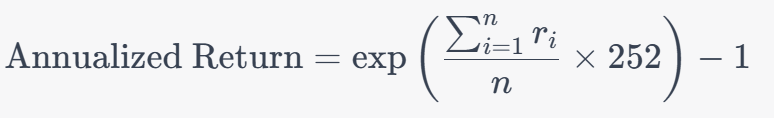

其中，$r_i$ 表示每个时间段的对数收益率，$n$ 表示总共的时间段数，常用的时间段数是252个交易日，因此需要乘以252来将日收益率转换为年收益率。

In [11]:
trading_days_per_year = 252 # 假设一年有252个交易日

annualized_return = np.exp(buy_and_hold_reuturn.mean() * trading_days_per_year) - 1 # 计算年化收益率
annualized_return

0.0233095536800505

In [12]:
print(f"年化收益率为：{annualized_return:.2%}")

年化收益率为：2.33%


使用算术平均收益率来计算年化收益率，可以采用以下公式：

$$annualizedreturn = (1 + arithmetic return)^{252} - 1$$

In [ ]:
Arithmetic_reuturn = (index_daily.close - index_daily.close.shift(1))/ index_daily.close.shift(1)
Arithmetic_reuturn = Arithmetic_reuturn.dropna()
annual_return = (1+Arithmetic_reuturn.mean())**252 - 1
print(f"年化收益率为：{annual_return:.2%}")

使用对数收益率相对于算术收益率有以下几个好处：

- 稳健性更强：对数收益率具有更好的稳健性，因为它对极端值的影响较小。而算术收益率受极端值的影响较大，容易受到离群值的干扰。

- 可加性更好：对数收益率是一种可加性更好的指标。即，多个时间段的对数收益率相加等于整个时间段的对数收益率。这对于跨越多个时间段的收益率计算非常有用。

- 更适合进行统计分析：对数收益率更适合用于一些统计学方法，例如正态性检验、协方差矩阵估计等。对数收益率可以使得数据更符合正态分布的假设，从而使得这些方法的结果更加可靠。

## annualized_volatility 
计算对数收益率的波动率可以使用标准差来衡量，具体步骤如下：

计算每个时间段的对数收益率，即 $r_i = \ln \frac{P_i}{P_{i-1}}$，其中 $P_i$ 表示第 $i$ 个时间点的价格。

计算对数收益率的平均值 $\mu = \frac{1}{n} \sum_{i=1}^{n} r_i$。

计算每个时间段的对数收益率与平均值的差值，即 $d_i = r_i - \mu$。

计算差值的平方和，即 $\sum_{i=1}^{n} d_i^2$。

计算标准差，即 $\sqrt{\frac{\sum_{i=1}^{n} d_i^2}{n-1}}$。

为了得到年化波动率，需要将标准差乘以一个常数，通常是 $\sqrt{252}$，因为一年有大约 252 个交易日。即 $\text{年化波动率} = \sqrt{252} \times \text{标准差}$。

In [13]:
annualized_volitiy = buy_and_hold_reuturn.std()*np.sqrt(trading_days_per_year)
annualized_volitiy

0.239259610449212

In [15]:
risk_free_rate = 0.01
SR= (annualized_return - risk_free_rate)/annualized_volitiy
SR

0.055628083883701454

# max drawdown

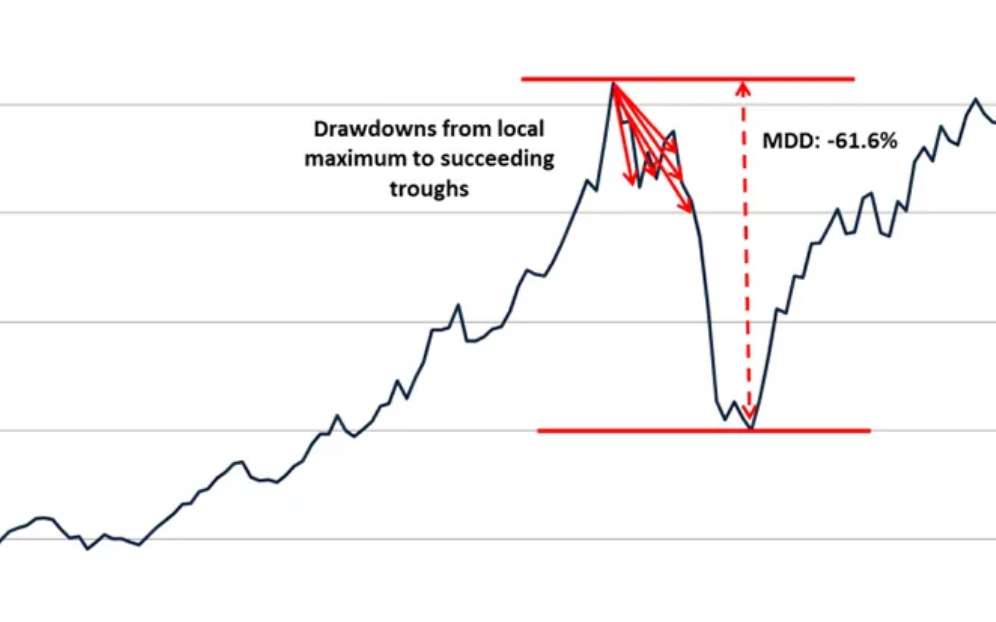

最大回撤（Maximum Drawdown）是一个投资组合或基金在一段时间内所经历的最大损失幅度，通常用于评估投资组合或基金的风险水平。理解最大回撤的概念对于投资者制定有效的风险管理策略非常重要。

最大回撤可以通过以下公式计算：

$MDD = \max_{i,j:i<j}\left(\frac{P_i-P_j}{P_i}\right)$

其中，$P_i$是投资组合或基金在时间$i$的净值。

最大回撤是指从投资组合或基金价值达到峰值到达谷底期间的最大百分比下跌。因此，最大回撤越大，意味着投资组合或基金的风险越高。比如，如果一个投资组合从100万美元跌至50万美元，最大回撤就是50%。

计算最大回撤的步骤如下：

- 计算投资组合每日净值（或每个交易日结束后的净值）。

- 计算每个交易日之前的最大净值，用于计算当前净值的回撤。

- 计算当前净值与之前最大净值之间的跌幅，得到回撤幅度。

- 计算所有回撤幅度的最大值，即为最大回撤。

In [16]:
import numpy as np

def max_drawdown(capital):
    """
    该函数计算最大回撤：财富的最大损失幅度
    capital：表示财富值，如果你已经计算出对数收益率为T，可以T.cumsum().apply(np.exp)计算累计财富值
    """
    max_capital = np.zeros(len(capital))
    drawdown = np.zeros(len(capital))
    max_drawdown = 0.0
    
    for i in range(1, len(capital)):
        max_capital[i] = max(max_capital[i-1], capital[i])
        drawdown[i] = (max_capital[i] - capital[i]) / max_capital[i]
        max_drawdown = max(max_drawdown, drawdown[i])
        
    return max_drawdown

In [17]:
capital = index_daily.log_return.cumsum().apply(np.exp)
max_drawdown(capital)

0.7198478280817133

# put all metrics we know together 

In [18]:
# 绩效指标
columns = ['年化收益率 % ','最大回撤 % ','夏普比率','年化波动率']
# 创建表格
finace_ret_df = pd.DataFrame(columns = columns)



# 定义函数：计算最大回撤
def max_drawdown(capital):
    """
    该函数计算最大回撤：财富的最大损失幅度
    capital：表示财富值，如果你已经计算出对数收益率为T，可以T.cumsum().apply(np.exp)计算累计财富值
    """
    max_capital = np.zeros(len(capital))
    drawdown = np.zeros(len(capital))
    max_drawdown = 0.0
    
    for i in range(1, len(capital)):
        max_capital[i] = max(max_capital[i-1], capital[i])
        drawdown[i] = (max_capital[i] - capital[i]) / max_capital[i]
        max_drawdown = max(max_drawdown, drawdown[i])
        
    return max_drawdown


# 设置函数：计算净值曲线的绩效指标
def get_Performance_analysis(T,year_day = 252):
    '''
    输入：T表示每日的收益率序列，每年的期数,我们默认是250个交易日
    
    输出：绩效指标
    '''

    # 计算年化收益率
    year_ret_mean = np.exp(T.dropna().mean() * year_day) - 1
    year_ret_mean = round(year_ret_mean*100,2)
    
    
    # 计算年化波动率
    volitiy = T.dropna().std()*np.sqrt(year_day)
    volitiy = round(volitiy*100,2)
    
    #计算夏普，无风险收益率记2%
    Sharpe = (year_ret_mean - 2)/volitiy
    Sharpe = round(Sharpe,2)

    # 计算最大回撤
    downlow = max_drawdown(T.cumsum().apply(np.exp))
    downlow = round(downlow*100,2)
    
    # 输出
    return [year_ret_mean,downlow,Sharpe,volitiy]


# 调用投资绩效分析函数
finace_ret_df.loc['bench_mark'] = get_Performance_analysis(T = index_daily["log_return"]) # buy and hold strategy
finace_ret_df

,年化收益率 %,最大回撤 %,夏普比率,年化波动率
bench_mark,2.3,71.98,0.01,23.92


**evaluate the seasonality strategy last week using the above metrics**

In [19]:
# 基于季节的投资策略的收益率保持在列seasonal_strategy_4stage_return中

index_daily["month"] = index_daily.index.month

# [2,4,11,12]
hold_month = [2,4,11,12]
def position_genrate(month):
    """
    该函数直接生成了每天的仓位，我们做其他策略时，建议分两步，首先生成交易信号，然后根据信号生成仓位
    """
    if month in set(hold_month):
        return 1
    else:
        return 0

# apply a function to a column to create a new variable
index_daily["position_4stage"] = index_daily.month.apply(position_genrate)

index_daily["seasonal_strategy_4stage_return"] = index_daily["position_4stage"] * index_daily["log_return"]

In [20]:
finace_ret_df.loc['seasonal_strategy'] = get_Performance_analysis(T = index_daily["seasonal_strategy_4stage_return"]) # buy and hold strategy
finace_ret_df

,年化收益率 %,最大回撤 %,夏普比率,年化波动率
bench_mark,2.30,71.98,0.01,23.92
seasonal_strategy,7.69,23.56,0.44,13.04


<AxesSubplot:xlabel='trade_date'>

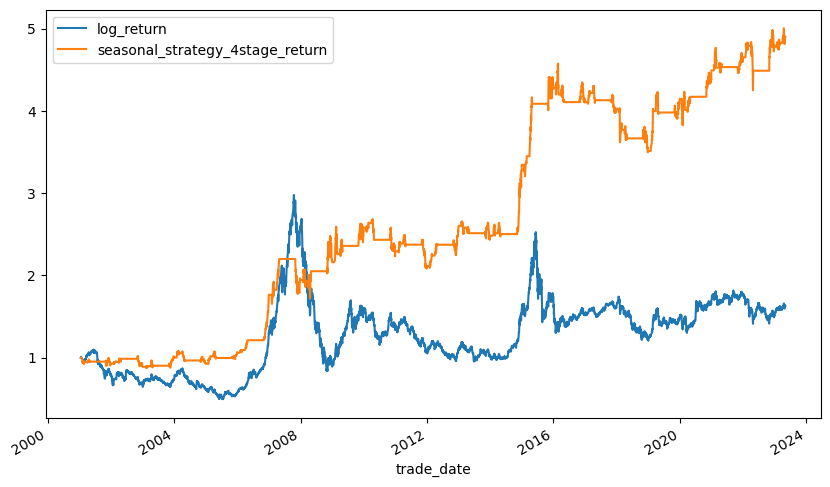

In [21]:
index_daily[["log_return","seasonal_strategy_4stage_return"]].cumsum().apply(np.exp).plot(figsize=(10,6))

# additional considerations for evaluating investment strategies

- 累计盈利图
- 胜率或盈利时间占比
- 参数的敏感性
- 收益率随着时间的变异性
- 预测力

## 累计盈利图 - 一图胜千言，从盈利图可以刊出，策略能否盈利、平稳性。

<img src = "../img/累计盈利图.png" align='left' height="400" width="500"/>

## 胜率或盈利时间占比
- 胜率告诉研究者系统盈利是来做小比例的偶然表现极其优秀的交易，还是来自很多交易，每笔交易都可能贡献微小的利润。
- 盈利时间占比：盈利周期与总周期的笔直简单度量。

例如：一个模型在65%的时间产生0信号，在19%的时间里产生盈利交易，在剩余的16%的时间里产生亏损交易。

因此，在非零信号的交易时间里，大约54%的时间里获得盈利。对于一个策略而言，这也不是一个太糟糕的结果。

## 参数的敏感性

策略通过改变参数，可能得到不同的结果。例如对于P/E策略，如果我们比值高于50（或为负值）应该是昂贵的，同时假定低于12的比率是便宜的。如果稍微调整上面的参数阈值，盈利结果发生很大变化，我们就应该对模型保持警惕。

因为如果模型被正面对于参数值的微笑改变过于敏感，在现实世界中没有什么使用价值。

## 收益率随着时间的变异性

该指标就是收益率的波动性，我们不仅可以使用天为单位，也可以使用季度和年为单位评估变异性：

假设在评价期间内有T个观察期，令t期内的收益率为rt，则投资策略的平均收益率可以很容易地计算出来。然后，可以使用以下公式来计算收益波动率：

$ \sqrt{\frac{\sum_{t=1}^{T}(r_t - \bar{r})^2}{T-1}} $

其中，$ \bar{r} $ 是策略的平均收益率。该标准差值可以被看作是投资策略的风险测度

## 预测力
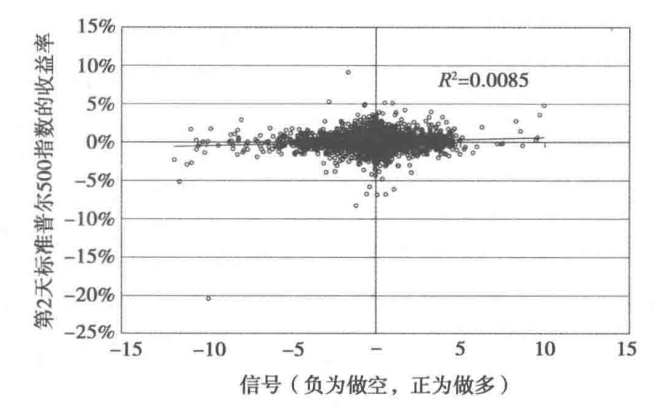

更常见的作法是对信号做分位数分为几组，然后评估每组内的平均收益率

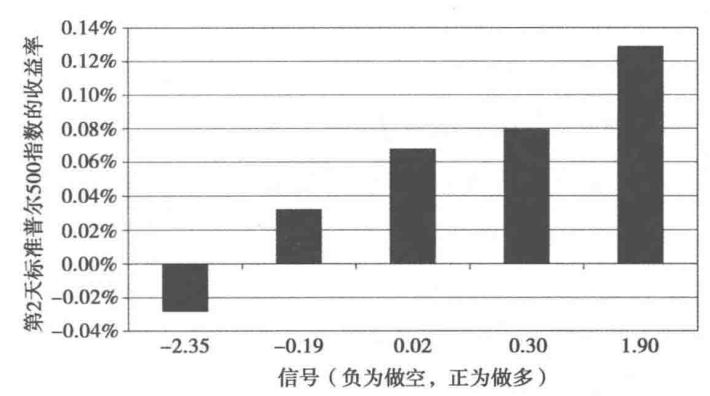


我们也可以使用他人开发的策略评价工具，例如pyfolio

# group report (15 - 20 minutes each group)
- technical indicator
- trading strategy
- total capital plot

常用的股票投资技术指标有很多，以下是其中一些常见的指标：

- 移动平均线（Moving Average，MA）
- 相对强弱指数（Relative Strength Index，RSI）
- 移动平均线收敛/发散指标（Moving Average Convergence Divergence，MACD）
- 布林带（Bollinger Bands）

要求：
- 指标的含义
- 指标的计算公式
- 如何根据技术指标做投资策略
- 下周随机邀请四位同学分享（2个同学1个小组）
- 在2011年之前的数据开发回测，在2011年开始的数据上进一步模拟交易
- data 参考如下

In [ ]:
import tushare as ts
import pandas as pd
token = 'aa6d7dba75bcd6eccd5bbda27e0cf6cf56c4759ec767990bdb041575'
ts.set_token(token)
pro = ts.pro_api()

start_date='20010101'
end_date='20230505'

index_daily = pro.index_daily(ts_code='000001.SH', start_date=start_date, end_date=end_date)
index_daily.trade_date = pd.DatetimeIndex(index_daily.trade_date)
index_daily.set_index("trade_date",inplace=True)
index_daily.sort_index(inplace=True)

# Evaluate your trading strategy after class
- evaluate your trading strategy using the metrics and some additional considerations 
- share your jupyter notebok (strategy and performance evaluation) in the QQ chat group